In [ ]:
"pip install tensorflow opencv-python numpy pandas matplotlib seaborn scikit-learn pillow"

In [3]:

import os
from pathlib import Path
import pandas as pd

# Dataset location
DATASET_PATH = Path(
    r"C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\brain_tumor"
)

TRAIN_PATH = DATASET_PATH / "classification_task" / "train"
TEST_PATH = DATASET_PATH / "classification_task" / "test"

classes = ["glioma", "meningioma", "pituitary", "no_tumor"]

print("Dataset exists:", DATASET_PATH.exists())

print("\nTRAINING DATA")

for category in classes:
    folder = TRAIN_PATH / category
    images = list(folder.glob("*.jpg"))
    print(category, ":", len(images))

print("\nTESTING DATA")

for category in classes:
    folder = TEST_PATH / category
    images = list(folder.glob("*.jpg"))
    print(category, ":", len(images))


Dataset exists: True

TRAINING DATA
glioma : 1147
meningioma : 1329
pituitary : 1457
no_tumor : 1067

TESTING DATA
glioma : 254
meningioma : 306
pituitary : 300
no_tumor : 140


In [4]:
from pathlib import Path

DATASET_PATH = Path(
    r"C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\brain_tumor"
)

TRAIN_PATH = DATASET_PATH / "classification_task" / "train"
TEST_PATH = DATASET_PATH / "classification_task" / "test"

CLASSES = ["glioma", "meningioma", "pituitary", "no_tumor"]

print("Dataset:", DATASET_PATH)
print("Training folder exists:", TRAIN_PATH.exists())
print("Testing folder exists:", TEST_PATH.exists())

Dataset: C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\brain_tumor
Training folder exists: True
Testing folder exists: True


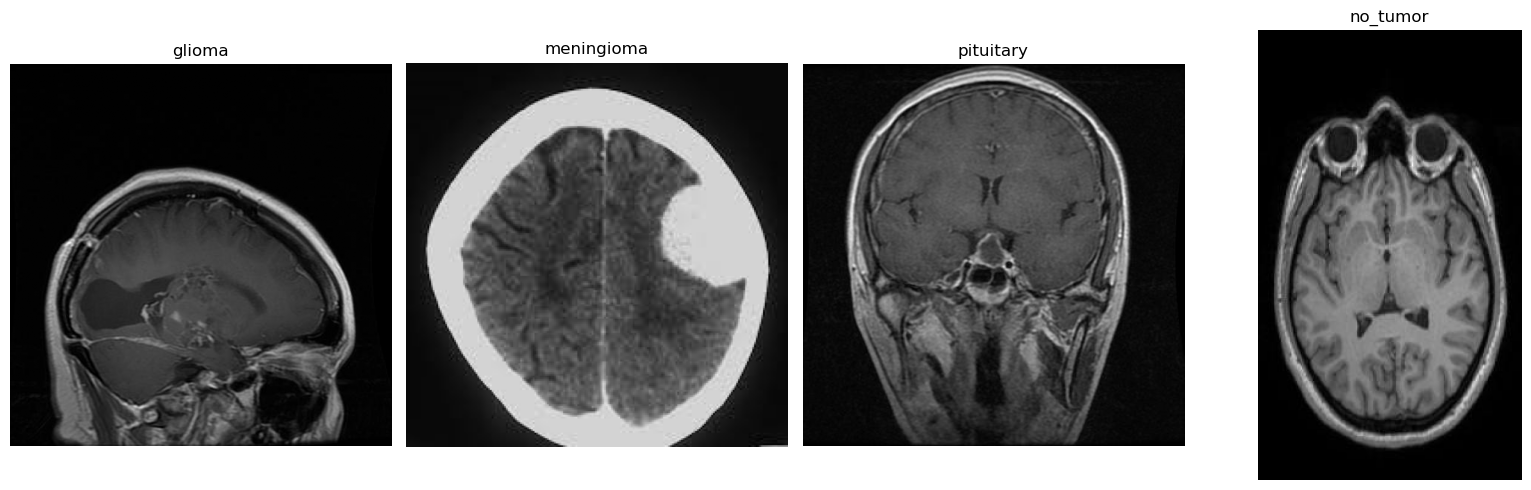

In [5]:
import matplotlib.pyplot as plt
from PIL import Image
import random

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for i, class_name in enumerate(CLASSES):

    image_files = list((TRAIN_PATH / class_name).glob("*"))

    image_path = random.choice(image_files)

    image = Image.open(image_path)

    axes[i].imshow(image, cmap="gray")
    axes[i].set_title(class_name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [6]:
from collections import Counter

dimensions = Counter()
formats = Counter()

for class_name in CLASSES:

    image_files = list((TRAIN_PATH / class_name).glob("*"))

    for image_path in image_files:

        try:
            with Image.open(image_path) as img:
                dimensions[img.size] += 1
                formats[img.format] += 1

        except Exception as e:
            print("Problem with:", image_path, e)

print("Image dimensions:")
print(dimensions.most_common(10))

print("\nImage formats:")
print(formats)

Image dimensions:
[((512, 512), 4120), ((369, 369), 323), ((216, 369), 277), ((256, 256), 27), ((187, 369), 21), ((202, 369), 19), ((225, 225), 13), ((210, 369), 12), ((236, 236), 11), ((442, 442), 6)]

Image formats:
Counter({'JPEG': 5000})


In [7]:
from collections import Counter
from PIL import Image
import pandas as pd

dimension_data = []

for class_name in CLASSES:
    folder = TRAIN_PATH / class_name

    for image_path in folder.iterdir():
        if image_path.is_file():
            try:
                with Image.open(image_path) as img:
                    dimension_data.append({
                        "class": class_name,
                        "width": img.width,
                        "height": img.height,
                        "format": img.format
                    })
            except Exception:
                print("Unreadable image:", image_path)

df_dimensions = pd.DataFrame(dimension_data)

print("Total readable images:", len(df_dimensions))

print("\nMost common dimensions by class:")
for class_name in CLASSES:
    print(f"\n{class_name}")
    print(
        df_dimensions[df_dimensions["class"] == class_name]
        .groupby(["width", "height"])
        .size()
        .sort_values(ascending=False)
        .head(10)
    )

Total readable images: 5000

Most common dimensions by class:

glioma
width  height
512    512       1147
dtype: int64

meningioma
width  height
512    512       1201
225    225          8
455    500          3
442    442          3
554    554          2
485    510          2
212    237          2
341    395          2
213    237          2
201    251          2
dtype: int64

pituitary
width  height
512    512       1418
256    256         24
474    474          2
201    210          1
202    202          1
360    378          1
400    400          1
442    442          1
470    432          1
502    502          1
dtype: int64

no_tumor
width  height
512    512       354
369    369       323
216    369       277
187    369        21
202    369        19
210    369        12
236    236        11
225    225         5
442    442         2
733    781         2
dtype: int64


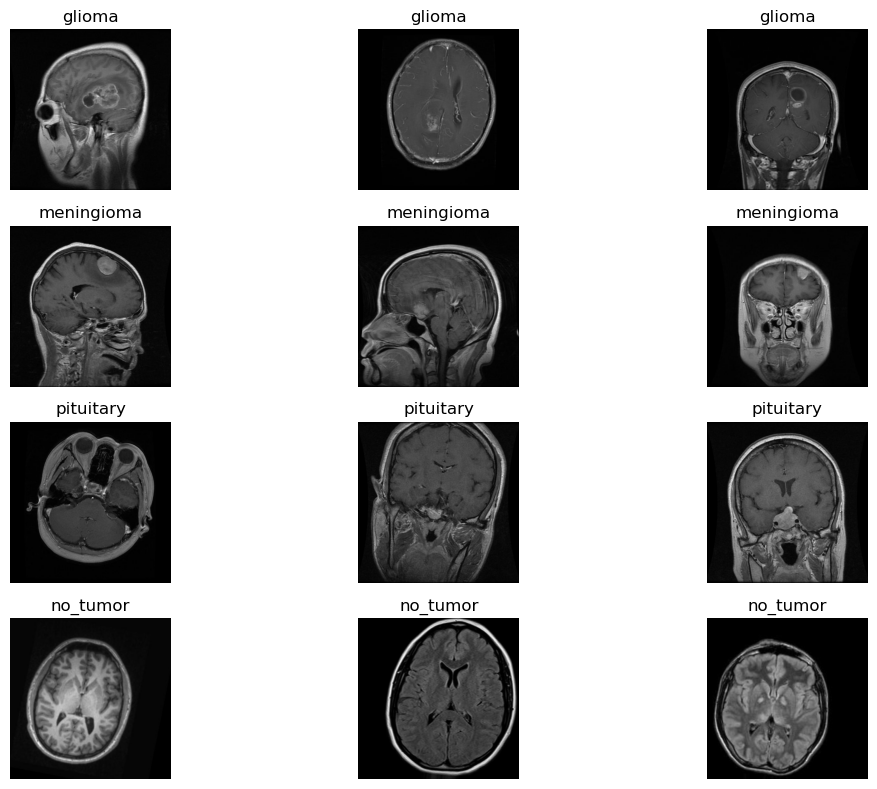

In [12]:
import matplotlib.pyplot as plt
import random
from PIL import Image

fig, axes = plt.subplots(4, 3, figsize=(12, 8))

for row, class_name in enumerate(CLASSES):

    image_files = [
        p for p in (TRAIN_PATH / class_name).iterdir()
        if p.is_file()
    ]

    samples = random.sample(image_files, min(3, len(image_files)))

    for col, image_path in enumerate(samples):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [13]:
from collections import Counter
import pandas as pd
from PIL import Image

def get_dimension_summary(folder, split_name):
    records = []

    for class_name in CLASSES:
        class_folder = folder / class_name

        for image_path in class_folder.iterdir():
            if image_path.is_file():
                try:
                    with Image.open(image_path) as img:
                        records.append({
                            "split": split_name,
                            "class": class_name,
                            "width": img.width,
                            "height": img.height
                        })
                except Exception:
                    print("Unreadable:", image_path)

    return pd.DataFrame(records)

train_dimensions = get_dimension_summary(TRAIN_PATH, "Train")
test_dimensions = get_dimension_summary(TEST_PATH, "Test")

all_dimensions = pd.concat(
    [train_dimensions, test_dimensions],
    ignore_index=True
)

summary = (
    all_dimensions
    .groupby(["split", "class", "width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values(["split", "class", "count"], ascending=[True, True, False])
)

print(summary.to_string(index=False))

split      class  width  height  count
 Test     glioma    512     512    254
 Test meningioma    512     512    188
 Test meningioma    225     225      7
 Test meningioma    442     442      4
 Test meningioma    201     251      3
 Test meningioma    210     240      3
 Test meningioma    554     554      3
 Test meningioma    200     223      2
 Test meningioma    212     237      2
 Test meningioma    228     221      2
 Test meningioma    341     395      2
 Test meningioma    455     500      2
 Test meningioma    174     230      1
 Test meningioma    200     235      1
 Test meningioma    200     236      1
 Test meningioma    200     252      1
 Test meningioma    201     207      1
 Test meningioma    204     249      1
 Test meningioma    205     251      1
 Test meningioma    206     245      1
 Test meningioma    206     249      1
 Test meningioma    208     243      1
 Test meningioma    209     241      1
 Test meningioma    211     239      1
 Test meningioma    212  

In [14]:
README_PATH = DATASET_PATH / "README.md"
MANIFEST_PATH = DATASET_PATH / "manifest.csv"

print("README exists:", README_PATH.exists())
print("Manifest exists:", MANIFEST_PATH.exists())

if README_PATH.exists():
    print("\n--- DATASET README ---")
    print(README_PATH.read_text(encoding="utf-8")[:10000])

if MANIFEST_PATH.exists():
    print("\n--- MANIFEST ---")
    manifest = pd.read_csv(MANIFEST_PATH)
    print(manifest.head())
    print("\nColumns:")
    print(manifest.columns.tolist())

README exists: True
Manifest exists: True

--- DATASET README ---
# BRISC 2025 — Brain Tumor MRI Dataset

> **BRISC** (BRain tumor Image Segmentation & Classification) — a curated, expert-annotated T1 MRI dataset for multi-class brain tumor classification and pixel-wise segmentation.

[ArXiv preprint (Fateh et al., 2025)](https://arxiv.org/abs/2506.14318)

---

## 🚀 Overview

BRISC is designed to address common shortcomings in existing public brain MRI collections (e.g., class imbalance, limited tumor types, and annotation inconsistency). It provides high-quality, physician-validated pixel-level masks and a balanced multi-class classification split, suitable for benchmarking segmentation and classification algorithms as well as multi-task learning research.

**Highlights**
- 6,000 T1-weighted MRI slices (5,000 train / 1,000 test)
- Four classes: **Glioma**, **Meningioma**, **Pituitary Tumor**, **No Tumor**
- Pixel-wise segmentation masks reviewed by radiologists
- Slices from three ana

In [15]:

import pandas as pd

# Load the dataset manifest
manifest = pd.read_csv(MANIFEST_PATH)

# Keep classification images only, excluding segmentation masks
classification = manifest[
    (manifest["task"] == "classification") &
    (manifest["is_mask"] == False)
].copy()

print("Total classification records:", len(classification))

# 1. Class distribution by split
print("\n--- CLASS DISTRIBUTION ---")
print(pd.crosstab(
    classification["tumor_label"],
    classification["split"],
    margins=True
))

# 2. Anatomical plane distribution
print("\n--- CLASS DISTRIBUTION BY PLANE ---")
print(pd.crosstab(
    [classification["tumor_label"], classification["split"]],
    classification["plane_label"]
))

# 3. Most common image dimensions by class
classification["dimensions"] = (
    classification["width"].astype(str)
    + "x"
    + classification["height"].astype(str)
)

print("\n--- DIMENSIONS BY CLASS AND SPLIT ---")
print(pd.crosstab(
    [classification["tumor_label"], classification["split"]],
    classification["dimensions"]
).to_string())

# 4. Duplicate hash audit across train and test
print("\n--- DUPLICATE HASH AUDIT ---")

hash_summary = classification.groupby("sha256").agg(
    occurrences=("sha256", "size"),
    splits=("split", "nunique"),
    filenames=("filename", "count")
)

duplicates = hash_summary[hash_summary["occurrences"] > 1]

cross_split_duplicates = hash_summary[
    (hash_summary["occurrences"] > 1) &
    (hash_summary["splits"] > 1)
]

print("Repeated image hashes:", len(duplicates))
print("Hashes appearing in both train and test:",
      len(cross_split_duplicates))


Total classification records: 6000

--- CLASS DISTRIBUTION ---
split        test  train   All
tumor_label                   
glioma        254   1147  1401
meningioma    306   1329  1635
no_tumor      140   1067  1207
pituitary     300   1457  1757
All          1000   5000  6000

--- CLASS DISTRIBUTION BY PLANE ---
plane_label        axial  coronal  sagittal
tumor_label split                          
glioma      test      85       81        88
            train    394      430       323
meningioma  test     137       86        83
            train    423      426       480
no_tumor    test      52       48        40
            train    352      310       405
pituitary   test     124       90        86
            train    426      510       521

--- DIMENSIONS BY CLASS AND SPLIT ---
dimensions         1024x1024  1149x1019  1275x1427  1280x1280  1365x1365  174x230  180x218  187x369  200x210  200x223  200x235  200x236  200x252  201x207  201x210  201x244  201x251  202x202  202x223  202x

In [16]:
# Find all repeated SHA-256 hashes
repeated_hashes = classification[
    classification.duplicated("sha256", keep=False)
].copy()

# Sort them so matching images appear together
repeated_hashes = repeated_hashes.sort_values(
    ["sha256", "split", "tumor_label"]
)

columns_to_show = [
    "sha256",
    "split",
    "tumor_label",
    "filename",
    "relative_path"
]

print("All repeated image records:")
display(repeated_hashes[columns_to_show])

# Show only hashes that occur in both train and test
cross_split_hashes = (
    repeated_hashes.groupby("sha256")["split"]
    .nunique()
)

cross_split_hashes = cross_split_hashes[
    cross_split_hashes > 1
].index

cross_split_duplicates = repeated_hashes[
    repeated_hashes["sha256"].isin(cross_split_hashes)
]

print("\nImages duplicated across training and testing:")
display(cross_split_duplicates[columns_to_show])

All repeated image records:


,sha256,split,tumor_label,filename,relative_path
826,02799f7863d49de182357e72179f3cc4e65e70099355f2...,test,pituitary,brisc2025_test_00827_pi_co_t1.jpg,classification_task\test\pituitary\brisc2025_t...
5193,02799f7863d49de182357e72179f3cc4e65e70099355f2...,train,pituitary,brisc2025_train_04194_pi_co_t1.jpg,classification_task\train\pituitary\brisc2025_...
750,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...,test,pituitary,brisc2025_test_00751_pi_ax_t1.jpg,classification_task\test\pituitary\brisc2025_t...
4748,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...,train,pituitary,brisc2025_train_03749_pi_ax_t1.jpg,classification_task\train\pituitary\brisc2025_...
4474,092a6997f62fdbaa2bc49469a827ef799ebd70cc75d1b0...,train,no_tumor,brisc2025_train_03475_no_sa_t1.jpg,classification_task\train\no_tumor\brisc2025_t...
...,...,...,...,...,...
2303,f3d00bbb942117c2fb62466414d3c466ca283b678200fe...,train,meningioma,brisc2025_train_01304_me_ax_t1.jpg,classification_task\train\meningioma\brisc2025...
414,f55311fb8ccf1b86450233262bd00b176bd1c404e5849b...,test,meningioma,brisc2025_test_00415_me_co_t1.jpg,classification_task\test\meningioma\brisc2025_...
415,f55311fb8ccf1b86450233262bd00b176bd1c404e5849b...,test,meningioma,brisc2025_test_00416_me_co_t1.jpg,classification_task\test\meningioma\brisc2025_...
2570,fce25282f9c298280721e6608db8dd49289984e7004b61...,train,meningioma,brisc2025_train_01571_me_co_t1.jpg,classification_task\train\meningioma\brisc2025...



Images duplicated across training and testing:


,sha256,split,tumor_label,filename,relative_path
826,02799f7863d49de182357e72179f3cc4e65e70099355f2...,test,pituitary,brisc2025_test_00827_pi_co_t1.jpg,classification_task\test\pituitary\brisc2025_t...
5193,02799f7863d49de182357e72179f3cc4e65e70099355f2...,train,pituitary,brisc2025_train_04194_pi_co_t1.jpg,classification_task\train\pituitary\brisc2025_...
750,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...,test,pituitary,brisc2025_test_00751_pi_ax_t1.jpg,classification_task\test\pituitary\brisc2025_t...
4748,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...,train,pituitary,brisc2025_train_03749_pi_ax_t1.jpg,classification_task\train\pituitary\brisc2025_...
736,39f4f7b252d7809d8d3d2e4521607de2195bf0f66c0592...,test,pituitary,brisc2025_test_00737_pi_ax_t1.jpg,classification_task\test\pituitary\brisc2025_t...
4704,39f4f7b252d7809d8d3d2e4521607de2195bf0f66c0592...,train,pituitary,brisc2025_train_03705_pi_ax_t1.jpg,classification_task\train\pituitary\brisc2025_...
824,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...,test,pituitary,brisc2025_test_00825_pi_co_t1.jpg,classification_task\test\pituitary\brisc2025_t...
5175,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...,train,pituitary,brisc2025_train_04176_pi_co_t1.jpg,classification_task\train\pituitary\brisc2025_...
5176,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...,train,pituitary,brisc2025_train_04177_pi_co_t1.jpg,classification_task\train\pituitary\brisc2025_...
5177,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...,train,pituitary,brisc2025_train_04178_pi_co_t1.jpg,classification_task\train\pituitary\brisc2025_...


In [17]:
# Group all records by their SHA-256 hash
duplicate_groups = (
    classification[
        classification.duplicated("sha256", keep=False)
    ]
    .groupby("sha256")
    .agg(
        count=("filename", "size"),
        labels=("tumor_label", "nunique"),
        label_names=("tumor_label", lambda x: list(x.unique())),
        splits=("split", lambda x: list(x.unique())),
        filenames=("filename", list)
    )
    .reset_index()
)

# Check for identical images assigned different labels
conflicting_labels = duplicate_groups[
    duplicate_groups["labels"] > 1
]

print("Repeated hash groups:", len(duplicate_groups))
print("Groups with conflicting class labels:", len(conflicting_labels))

display(conflicting_labels)

Repeated hash groups: 46
Groups with conflicting class labels: 0


,sha256,count,labels,label_names,splits,filenames


In [18]:
# Keep the original test set unchanged
test_df = classification[
    classification["split"] == "test"
].copy()

# Identify all hashes present in the test set
test_hashes = set(test_df["sha256"])

# Remove training images that also occur in the test set
train_df = classification[
    (classification["split"] == "train") &
    (~classification["sha256"].isin(test_hashes))
].copy()

# Remove repeated images within the remaining training set
train_df = train_df.drop_duplicates(
    subset="sha256",
    keep="first"
).copy()

print("Original training images:", 5000)
print("Cleaned training images:", len(train_df))
print("Original testing images:", len(test_df))
print("Testing images retained:", len(test_df))

print("\nCleaned training distribution:")
print(train_df["tumor_label"].value_counts())

print("\nTesting distribution:")
print(test_df["tumor_label"].value_counts())

# Verify no exact hash overlap remains
overlap = set(train_df["sha256"]) & set(test_df["sha256"])

print("\nRemaining train-test hash overlap:", len(overlap))

Original training images: 5000
Cleaned training images: 4955
Original testing images: 1000
Testing images retained: 1000

Cleaned training distribution:
tumor_label
pituitary     1440
meningioma    1310
glioma        1147
no_tumor      1058
Name: count, dtype: int64

Testing distribution:
tumor_label
meningioma    306
pituitary     300
glioma        254
no_tumor      140
Name: count, dtype: int64

Remaining train-test hash overlap: 0


In [19]:

from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd

# Convert manifest paths into usable local file paths
def make_filepath(relative_path):
    parts = str(relative_path).replace("\\", "/").split("/")
    return str(DATASET_PATH.joinpath(*parts))

train_df = train_df.copy()
test_df = test_df.copy()

train_df["filepath"] = train_df["relative_path"].apply(make_filepath)
test_df["filepath"] = test_df["relative_path"].apply(make_filepath)

# Verify all image paths exist
print("Training files exist:",
      train_df["filepath"].apply(lambda p: Path(p).is_file()).all())

print("Testing files exist:",
      test_df["filepath"].apply(lambda p: Path(p).is_file()).all())

# Stratified 80/20 split
train_split, val_split = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42,
    stratify=train_df["tumor_label"]
)

print("\nTraining images:", len(train_split))
print("Validation images:", len(val_split))
print("Testing images:", len(test_df))

print("\nTraining distribution:")
print(train_split["tumor_label"].value_counts())

print("\nValidation distribution:")
print(val_split["tumor_label"].value_counts())


Training files exist: True
Testing files exist: True

Training images: 3964
Validation images: 991
Testing images: 1000

Training distribution:
tumor_label
pituitary     1152
meningioma    1048
glioma         918
no_tumor       846
Name: count, dtype: int64

Validation distribution:
tumor_label
pituitary     288
meningioma    262
glioma        229
no_tumor      212
Name: count, dtype: int64


In [20]:

PROJECT_PATH = DATASET_PATH.parent
OUTPUT_PATH = PROJECT_PATH / "processed_data"

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

train_split.to_csv(
    OUTPUT_PATH / "train_split.csv", index=False
)

val_split.to_csv(
    OUTPUT_PATH / "validation_split.csv", index=False
)

test_df.to_csv(
    OUTPUT_PATH / "test_manifest.csv", index=False
)

print("Split files saved in:", OUTPUT_PATH)


Split files saved in: C:\Users\Chaithanya Reddy\Projects\Brain_Tumor_AI_Project\processed_data


In [21]:
import sys
import platform

print("Python version:", sys.version)
print("Operating system:", platform.platform())

try:
    import tensorflow as tf

    print("TensorFlow version:", tf.__version__)
    print("Available GPUs:", tf.config.list_physical_devices("GPU"))

except ImportError:
    print("TensorFlow is not installed.")

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Operating system: Windows-11-10.0.26200-SP0
TensorFlow version: 2.21.0
Available GPUs: []


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("TensorFlow:", tf.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pillow:", Image.__version__ if hasattr(Image, "__version__") else "Installed")

NumPy: 2.3.5
Pandas: 2.3.3
Matplotlib: 3.10.6
TensorFlow: 2.21.0
Scikit-learn: 1.7.2
Pillow: 12.0.0


In [24]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = 224
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Classes:", CLASSES)

Image size: 224
Batch size: 8
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [29]:
def preprocess_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [26]:
class_to_index = {
    name: index
    for index, name in enumerate(CLASSES)
}

def prepare_dataframe(df):
    paths = df["filepath"].astype(str).values

    labels = (
        df["tumor_label"]
        .map(class_to_index)
        .astype("int32")
        .values
    )

    return paths, labels

train_paths, train_labels = prepare_dataframe(train_split)
val_paths, val_labels = prepare_dataframe(val_split)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

Training images: 3964
Validation images: 991


In [27]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = (
    train_ds
    .shuffle(1000, seed=42)
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = (
    val_ds
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Training and validation datasets created!")

Training and validation datasets created!


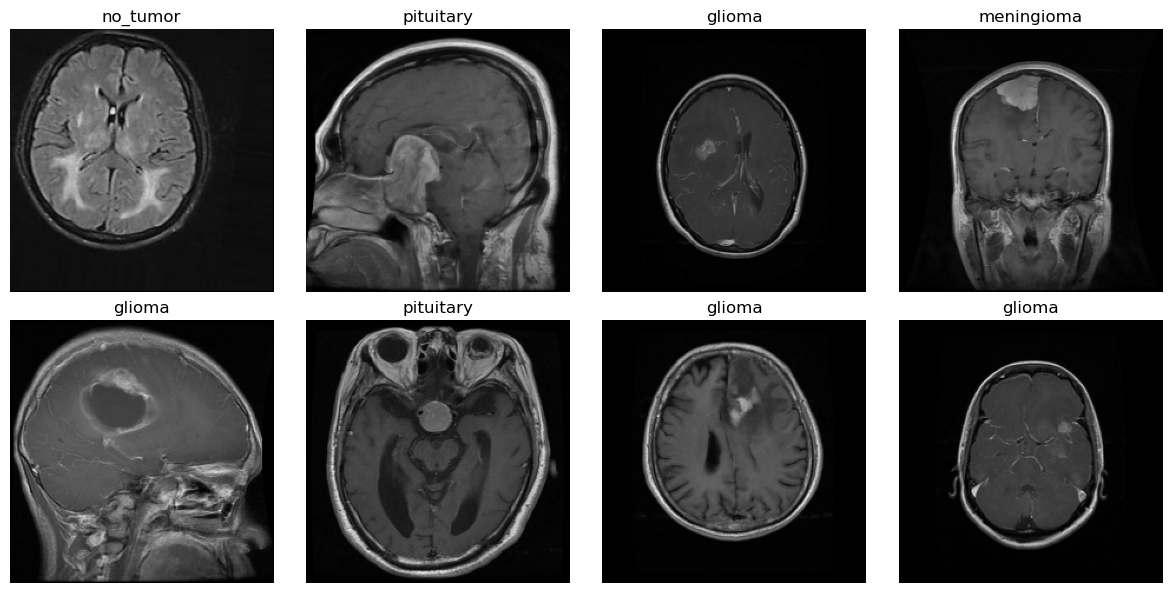

In [30]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 6))

for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i].numpy())

    class_name = CLASSES[int(labels[i].numpy())]

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.03,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.08,
        width_factor=0.08,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomContrast(
        factor=0.1
    )
])

print("Data augmentation created!")

Data augmentation created!


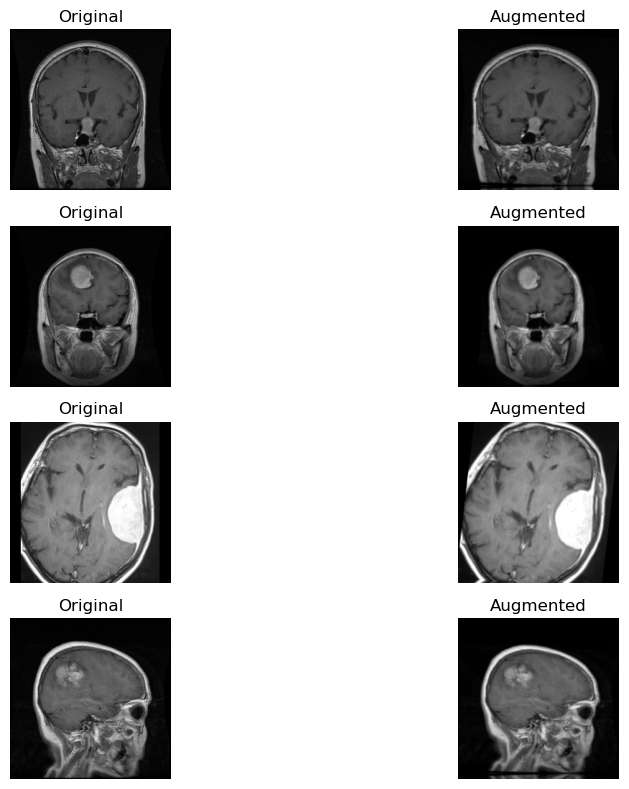

In [32]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(4):
    original = images[i]

    augmented = data_augmentation(
        tf.expand_dims(original, axis=0),
        training=True
    )[0]

    # Original image
    plt.subplot(4, 2, 2*i + 1)
    plt.imshow(original.numpy())
    plt.title("Original")
    plt.axis("off")

    # Augmented image
    plt.subplot(4, 2, 2*i + 2)
    plt.imshow(
        tf.clip_by_value(augmented, 0, 1).numpy()
    )
    plt.title("Augmented")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
from tensorflow.keras import layers, models

NUM_CLASSES = 4

cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 4
    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [35]:
total_params = cnn_model.count_params()

print("Total parameters:", total_params)

Total parameters: 421828


In [38]:
with open(
    "cnn_model_summary.txt",
    "w",
    encoding="utf-8"
) as f:
    cnn_model.summary(
        print_fn=lambda x: f.write(x + "\n")
    )

print("Model summary saved successfully!")

Model summary saved successfully!


In [39]:
def augment_image(image, label):
    image = data_augmentation(
        image,
        training=True
    )
    return image, label

train_ds_aug = (
    train_ds
    .map(augment_image, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

In [40]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001
    ),

    ModelCheckpoint(
        "best_cnn_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

print("Training callbacks configured!")

Training callbacks configured!


In [41]:
history = cnn_model.fit(
    train_ds_aug,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15


D:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


496/496 ━━━━━━━━━━━━━━━━━━━━ 142s 280ms/step - accuracy: 0.4316 - loss: 1.2540 - val_accuracy: 0.4854 - val_loss: 1.2000 - learning_rate: 0.0010
Epoch 2/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 137s 275ms/step - accuracy: 0.5257 - loss: 1.0906 - val_accuracy: 0.5530 - val_loss: 1.0617 - learning_rate: 0.0010
Epoch 3/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 129s 260ms/step - accuracy: 0.6239 - loss: 0.8923 - val_accuracy: 0.7366 - val_loss: 0.7574 - learning_rate: 0.0010
Epoch 4/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 145s 292ms/step - accuracy: 0.6655 - loss: 0.8137 - val_accuracy: 0.6993 - val_loss: 0.7842 - learning_rate: 0.0010
Epoch 5/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 127s 256ms/step - accuracy: 0.6847 - loss: 0.7473 - val_accuracy: 0.7003 - val_loss: 0.7850 - learning_rate: 0.0010
Epoch 6/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 150s 302ms/step - accuracy: 0.7154 - loss: 0.6900 - val_accuracy: 0.6498 - val_loss: 0.7934 - learning_rate: 5.0000e-04
Epoch 7/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 148s 297ms/step - accuracy: 0.7

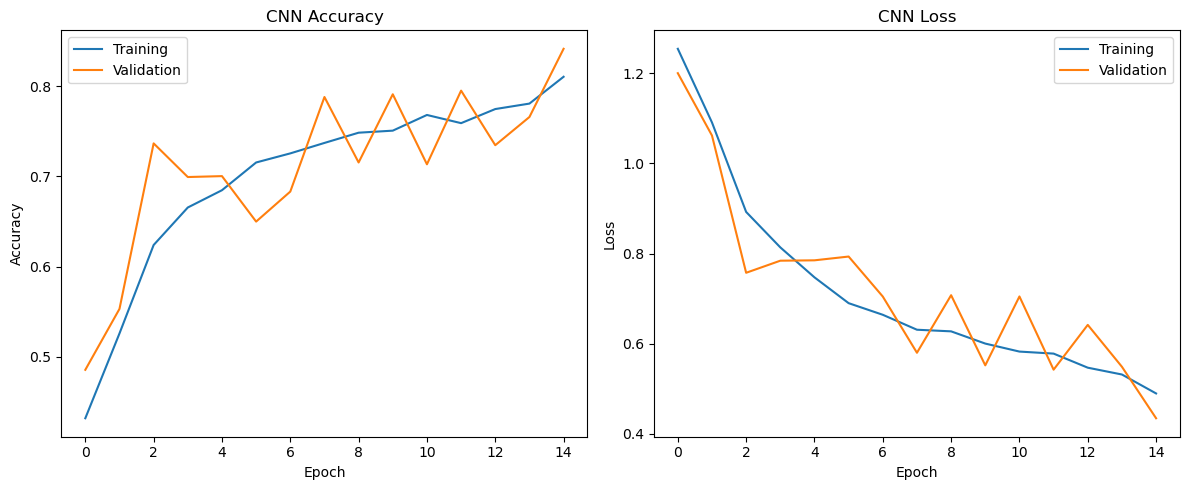

In [42]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [43]:
best_cnn = tf.keras.models.load_model(
    "best_cnn_model.keras"
)

print("Best CNN model loaded!")

Best CNN model loaded!


In [44]:
import numpy as np

y_true = val_labels

y_prob = best_cnn.predict(val_ds)

y_pred = np.argmax(y_prob, axis=1)

print("Predictions completed!")
print("Number of predictions:", len(y_pred))

124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step
Predictions completed!
Number of predictions: 991


In [45]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASSES,
        digits=4
    )
)

              precision    recall  f1-score   support

      glioma     0.8864    0.6812    0.7704       229
  meningioma     0.7256    0.7672    0.7458       262
    no_tumor     0.9384    0.9340    0.9362       212
   pituitary     0.8532    0.9688    0.9073       288

    accuracy                         0.8416       991
   macro avg     0.8509    0.8378    0.8399       991
weighted avg     0.8454    0.8416    0.8391       991



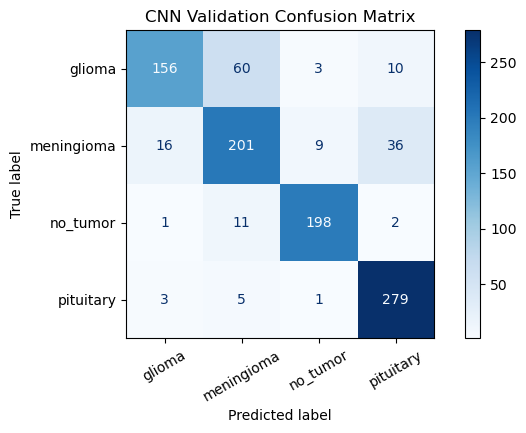

In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

fig, ax = plt.subplots(figsize=(8, 4))

display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("CNN Validation Confusion Matrix")
plt.xticks(rotation=30)
plt.show()

In [48]:
import json

best_cnn.save("baseline_cnn_model.keras")

with open("cnn_validation_report.json", "w") as f:
    json.dump(
        classification_report(
            y_true,
            y_pred,
            target_names=CLASSES,
            output_dict=True
        ),
        f,
        indent=4
    )

print("Baseline CNN and evaluation report saved!")

Baseline CNN and evaluation report saved!


In [49]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("MobileNetV2 loaded!")
print("Base model layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 loaded!
Base model layers: 154


In [50]:
from tensorflow.keras import layers, Model

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# Convert [0, 1] to [-1, 1]
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    4,
    activation="softmax"
)(x)

mobilenet_model = Model(
    inputs=inputs,
    outputs=outputs
)

mobilenet_model.summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [51]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 compiled successfully!")

MobileNetV2 compiled successfully!


In [52]:
mobilenet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.000001
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_mobilenet_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

In [53]:
mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=mobilenet_callbacks
)

Epoch 1/12


D:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


496/496 ━━━━━━━━━━━━━━━━━━━━ 123s 234ms/step - accuracy: 0.6367 - loss: 0.9027 - val_accuracy: 0.7820 - val_loss: 0.5730 - learning_rate: 1.0000e-04
Epoch 2/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 116s 233ms/step - accuracy: 0.7876 - loss: 0.5571 - val_accuracy: 0.8123 - val_loss: 0.4935 - learning_rate: 1.0000e-04
Epoch 3/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 138s 278ms/step - accuracy: 0.8257 - loss: 0.4621 - val_accuracy: 0.8365 - val_loss: 0.4538 - learning_rate: 1.0000e-04
Epoch 4/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 126s 254ms/step - accuracy: 0.8317 - loss: 0.4358 - val_accuracy: 0.8567 - val_loss: 0.4150 - learning_rate: 1.0000e-04
Epoch 5/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 152s 306ms/step - accuracy: 0.8544 - loss: 0.3900 - val_accuracy: 0.8375 - val_loss: 0.4593 - learning_rate: 1.0000e-04
Epoch 6/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 134s 269ms/step - accuracy: 0.8650 - loss: 0.3541 - val_accuracy: 0.8698 - val_loss: 0.3824 - learning_rate: 1.0000e-04
Epoch 7/12
496/496 ━━━━━━━━━━━━━━━━━━━━ 103s 207ms/

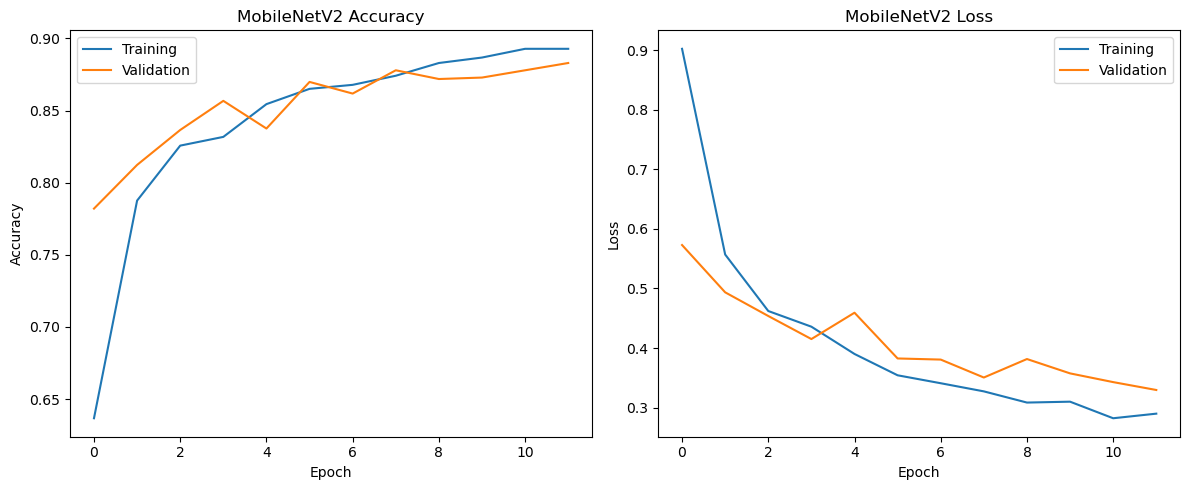

In [54]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    mobilenet_history.history["accuracy"],
    label="Training"
)
plt.plot(
    mobilenet_history.history["val_accuracy"],
    label="Validation"
)
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    mobilenet_history.history["loss"],
    label="Training"
)
plt.plot(
    mobilenet_history.history["val_loss"],
    label="Validation"
)
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [55]:
best_mobilenet = tf.keras.models.load_model(
    "best_mobilenet_model.keras"
)

print("Best MobileNetV2 loaded!")

Best MobileNetV2 loaded!


In [56]:
mobilenet_y_prob = best_mobilenet.predict(val_ds)

mobilenet_y_pred = np.argmax(
    mobilenet_y_prob,
    axis=1
)

print("Predictions completed!")

124/124 ━━━━━━━━━━━━━━━━━━━━ 26s 195ms/step
Predictions completed!


In [57]:
from sklearn.metrics import classification_report

print(
    classification_report(
        val_labels,
        mobilenet_y_pred,
        target_names=CLASSES,
        digits=4
    )
)

              precision    recall  f1-score   support

      glioma     0.9261    0.8210    0.8704       229
  meningioma     0.7829    0.8397    0.8103       262
    no_tumor     0.9740    0.8821    0.9257       212
   pituitary     0.8889    0.9722    0.9287       288

    accuracy                         0.8829       991
   macro avg     0.8930    0.8787    0.8838       991
weighted avg     0.8877    0.8829    0.8833       991



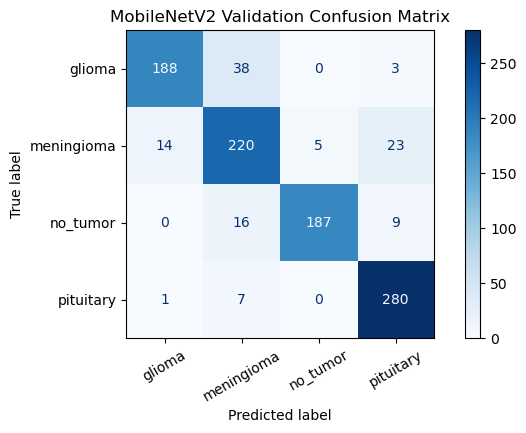

In [59]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

mobilenet_cm = confusion_matrix(
    val_labels,
    mobilenet_y_pred
)

fig, ax = plt.subplots(figsize=(8, 4))

disp = ConfusionMatrixDisplay(
    confusion_matrix=mobilenet_cm,
    display_labels=CLASSES
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("MobileNetV2 Validation Confusion Matrix")
plt.xticks(rotation=30)
plt.show()

In [60]:
best_mobilenet = tf.keras.models.load_model(
    "best_mobilenet_model.keras"
)

print("Best MobileNetV2 loaded!")

Best MobileNetV2 loaded!


In [61]:
base_model = best_mobilenet.get_layer(
    "mobilenetv2_1.00_224"
)

base_model.trainable = True

# Freeze all but the final 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print(
    "Trainable base layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Trainable base layers: 19


In [62]:
best_mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled!")

Fine-tuning model compiled!


In [63]:
fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_finetuned_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7
    )
]

fine_tune_history = best_mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=fine_tune_callbacks
)

Epoch 1/8


D:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


496/496 ━━━━━━━━━━━━━━━━━━━━ 145s 276ms/step - accuracy: 0.9021 - loss: 0.2707 - val_accuracy: 0.8708 - val_loss: 0.3722 - learning_rate: 1.0000e-05
Epoch 2/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 124s 250ms/step - accuracy: 0.9122 - loss: 0.2314 - val_accuracy: 0.8930 - val_loss: 0.2793 - learning_rate: 1.0000e-05
Epoch 3/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 161s 324ms/step - accuracy: 0.9213 - loss: 0.2026 - val_accuracy: 0.8971 - val_loss: 0.2786 - learning_rate: 1.0000e-05
Epoch 4/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 127s 256ms/step - accuracy: 0.9321 - loss: 0.1719 - val_accuracy: 0.9112 - val_loss: 0.2252 - learning_rate: 1.0000e-05
Epoch 5/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 460s 929ms/step - accuracy: 0.9448 - loss: 0.1520 - val_accuracy: 0.9122 - val_loss: 0.2338 - learning_rate: 1.0000e-05
Epoch 6/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 125s 252ms/step - accuracy: 0.9528 - loss: 0.1307 - val_accuracy: 0.9193 - val_loss: 0.2189 - learning_rate: 1.0000e-05
Epoch 7/8
496/496 ━━━━━━━━━━━━━━━━━━━━ 128s 259ms/step -

In [64]:
best_finetuned = tf.keras.models.load_model(
    "best_finetuned_model.keras"
)

print("Best fine-tuned model loaded!")

Best fine-tuned model loaded!


In [65]:
finetuned_prob = best_finetuned.predict(val_ds)

finetuned_pred = np.argmax(
    finetuned_prob,
    axis=1
)

124/124 ━━━━━━━━━━━━━━━━━━━━ 31s 224ms/step


In [66]:
from sklearn.metrics import classification_report

finetuned_report = classification_report(
    val_labels,
    finetuned_pred,
    target_names=CLASSES,
    digits=4
)

print(finetuned_report)

              precision    recall  f1-score   support

      glioma     0.9442    0.8865    0.9144       229
  meningioma     0.8831    0.8359    0.8588       262
    no_tumor     0.9854    0.9528    0.9688       212
   pituitary     0.8885    0.9965    0.9394       288

    accuracy                         0.9193       991
   macro avg     0.9253    0.9179    0.9204       991
weighted avg     0.9207    0.9193    0.9186       991



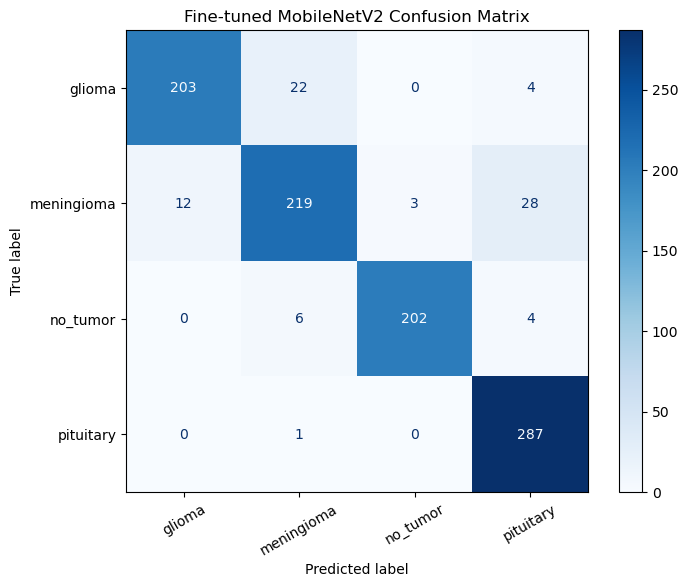

In [67]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

finetuned_cm = confusion_matrix(
    val_labels,
    finetuned_pred
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=finetuned_cm,
    display_labels=CLASSES
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Fine-tuned MobileNetV2 Confusion Matrix")
plt.xticks(rotation=30)
plt.show()

In [68]:
best_finetuned.save(
    "final_brain_tumor_model.keras"
)

print("Final candidate model saved!")

Final candidate model saved!


In [69]:
best_finetuned.save(
    "final_brain_tumor_model.keras"
)

print("Fine-tuned model saved successfully!")

Fine-tuned model saved successfully!


In [70]:
# Get the MobileNetV2 base model
base_model = best_finetuned.get_layer(
    "mobilenetv2_1.00_224"
)

# Reconstruct the model path so we can access
# both convolutional features and predictions
inputs = best_finetuned.input

x = best_finetuned.get_layer("sequential")(inputs)
x = best_finetuned.get_layer("rescaling")(x)

feature_maps = base_model(x, training=False)

x = best_finetuned.get_layer(
    "global_average_pooling2d_1"
)(feature_maps)

x = best_finetuned.get_layer("dropout_1")(x, training=False)
x = best_finetuned.get_layer("dense_2")(x)
x = best_finetuned.get_layer("dropout_2")(x, training=False)

predictions = best_finetuned.get_layer("dense_3")(x)

grad_model = tf.keras.Model(
    inputs=inputs,
    outputs=[feature_maps, predictions]
)

print("Grad-CAM model created!")

Grad-CAM model created!


In [71]:
def generate_gradcam(image_tensor, model):

    with tf.GradientTape() as tape:

        conv_outputs, predictions = model(
            image_tensor,
            training=False
        )

        predicted_class = tf.argmax(
            predictions[0]
        )

        class_score = predictions[:, predicted_class]

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    # Average gradients across spatial dimensions
    weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    # Weighted combination of feature maps
    cam = tf.reduce_sum(
        conv_outputs[0] * weights,
        axis=-1
    )

    # Keep positive activations
    cam = tf.maximum(cam, 0)

    # Normalize heatmap
    cam = cam / (
        tf.reduce_max(cam) + 1e-8
    )

    return cam.numpy(), predictions.numpy()[0]

In [72]:
# Get one validation batch
images, labels = next(iter(val_ds))

# Select the first image
sample_image = images[0:1]
actual_label = int(labels[0].numpy())

# Generate heatmap
heatmap, probabilities = generate_gradcam(
    sample_image,
    grad_model
)

predicted_label = int(np.argmax(probabilities))

print("Actual class:", CLASSES[actual_label])
print("Predicted class:", CLASSES[predicted_label])
print(
    "Confidence:",
    round(float(probabilities[predicted_label]) * 100, 2),
    "%"
)

Actual class: meningioma
Predicted class: meningioma
Confidence: 57.96 %


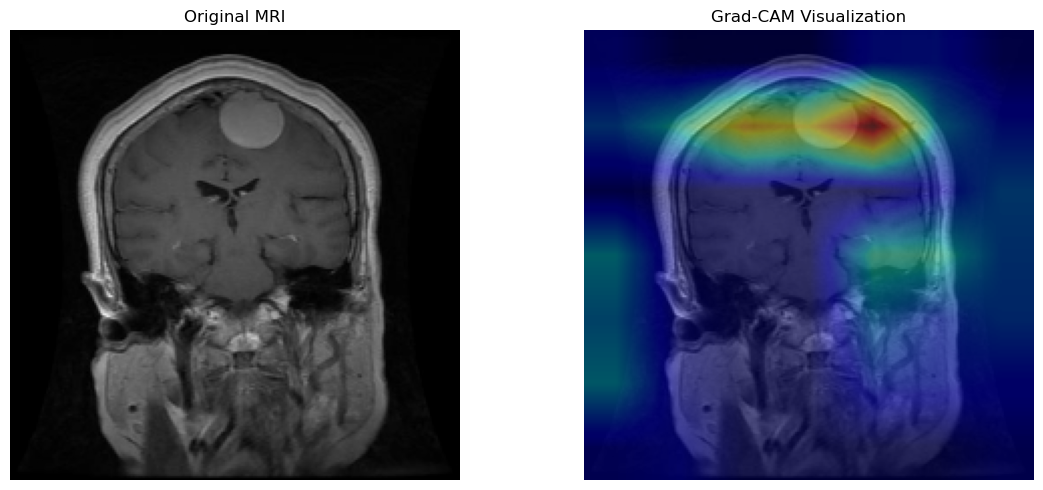

In [73]:
# Resize heatmap to original image size
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

original_image = sample_image[0].numpy()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.4
)
plt.title("Grad-CAM Visualization")
plt.axis("off")

plt.tight_layout()
plt.show()

In [74]:
print("Test images:", test_df.shape[0])
print("Classes:", CLASSES)
print("Test dataset available:", "test_ds" in globals())

Test images: 1000
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Test dataset available: False


In [78]:
import tensorflow as tf
import numpy as np

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 8

# Convert class names into numerical labels
class_to_index = {
    name: index for index, name in enumerate(CLASSES)
}

# Get image paths and labels from the test manifest
test_paths = test_df["filepath"].astype(str).values

test_labels = test_df["tumor_label"].map(
    class_to_index
).values.astype("int32")

# Load and resize images
def load_test_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    return image, label

# Create the test dataset
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Test dataset created successfully!")
print("Number of test images:", len(test_paths))
print("Classes:", CLASSES)

Test dataset created successfully!
Number of test images: 1000
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [79]:
for images, labels in test_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image value range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

Image batch shape: (8, 224, 224, 3)
Label batch shape: (8,)
Image value range: 0.0 to 251.43392944335938


In [80]:
test_predictions = best_finetuned.predict(test_ds)

y_pred = np.argmax(test_predictions, axis=1)

y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

print("Predictions completed!")
print("Predictions:", len(y_pred))
print("Actual labels:", len(y_true))

125/125 ━━━━━━━━━━━━━━━━━━━━ 23s 187ms/step
Predictions completed!
Predictions: 1000
Actual labels: 1000


In [81]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate accuracy
test_accuracy = accuracy_score(y_true, y_pred)

print("FINAL TEST ACCURACY:",
      round(test_accuracy * 100, 2), "%")

# Classification report
print("\nFINAL TEST CLASSIFICATION REPORT:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(CLASSES)),
    target_names=CLASSES,
    digits=4
))

FINAL TEST ACCURACY: 15.3 %

FINAL TEST CLASSIFICATION REPORT:

              precision    recall  f1-score   support

      glioma     0.0000    0.0000    0.0000       254
  meningioma     0.4000    0.0327    0.0604       306
    no_tumor     0.1440    1.0000    0.2518       140
   pituitary     1.0000    0.0100    0.0198       300

    accuracy                         0.1530      1000
   macro avg     0.3860    0.2607    0.0830      1000
weighted avg     0.4426    0.1530    0.0597      1000



D:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


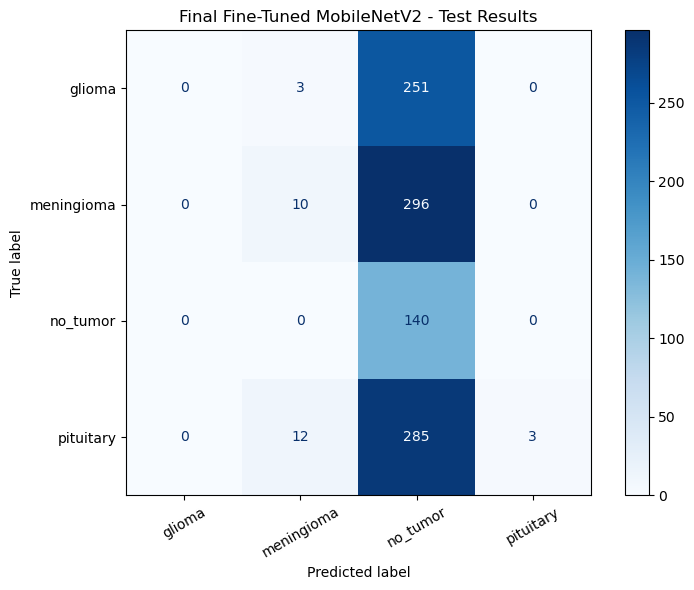

In [82]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(CLASSES))
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Final Fine-Tuned MobileNetV2 - Test Results")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [83]:
# 1. Inspect the model's preprocessing layers
print("MODEL PREPROCESSING LAYERS\n")

for layer in best_finetuned.layers:
    if isinstance(layer, tf.keras.Sequential) or "rescal" in layer.name.lower():
        print("\nLayer:", layer.name)
        print("Configuration:", layer.get_config())

# 2. Compare validation and test image ranges
val_images, val_labels = next(iter(val_ds))
test_images, test_labels = next(iter(test_ds))

print("\nIMAGE COMPARISON")
print("Validation range:",
      float(tf.reduce_min(val_images)),
      "to",
      float(tf.reduce_max(val_images)))

print("Test range:",
      float(tf.reduce_min(test_images)),
      "to",
      float(tf.reduce_max(test_images)))

# 3. Compare predictions on both datasets
val_probs = best_finetuned.predict(val_images, verbose=0)
test_probs = best_finetuned.predict(test_images, verbose=0)

print("\nPREDICTION CLASS DISTRIBUTION")

print("Validation predictions:",
      np.bincount(np.argmax(val_probs, axis=1),
                  minlength=len(CLASSES)))

print("Test predictions:",
      np.bincount(np.argmax(test_probs, axis=1),
                  minlength=len(CLASSES)))

print("\nCLASS ORDER:", CLASSES)

MODEL PREPROCESSING LAYERS


Layer: sequential
Configuration: {'name': 'sequential', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_shape': (1, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_layer', 'optional': False}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'data_format': 'channels_last', 'factor': (-0.03, 0.03), 'fill_mode': 'reflect', 'fill_value': 0.0, 'interpolation': 'bilinear', 'seed': None}, 'registered_name': None, 'build_config': {'input_shape': [1, 224, 224, 3]}}, {'module': 'keras.layers', 'class_name': 'RandomZoom', 'config': {'name': 'random_zoom', 'traina

In [84]:
print("Test label distribution:")

print(
    test_df["tumor_label"].value_counts()
)

print("\nNumerical label mapping:")

for index, name in enumerate(CLASSES):
    print(index, "=", name)

Test label distribution:
tumor_label
meningioma    306
pituitary     300
glioma        254
no_tumor      140
Name: count, dtype: int64

Numerical label mapping:
0 = glioma
1 = meningioma
2 = no_tumor
3 = pituitary


In [85]:
def load_test_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        (224, 224)
    )

    # Match the validation preprocessing
    image = image / 255.0

    return image, label

In [86]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(8)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Corrected test dataset created!")

ValueError: Dimensions 1000 and 8 are not compatible

In [87]:
# Recreate test image paths
test_paths = test_df["filepath"].astype(str).values

# Recreate all 1000 numerical labels
class_to_index = {
    name: index for index, name in enumerate(CLASSES)
}

test_labels = test_df["tumor_label"].map(
    class_to_index
).values.astype("int32")

# Verify lengths
print("Test paths:", len(test_paths))
print("Test labels:", len(test_labels))

assert len(test_paths) == len(test_labels) == 1000

print("Test variables verified!")

Test paths: 1000
Test labels: 1000
Test variables verified!


In [88]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(8)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Corrected test dataset created!")

Corrected test dataset created!


In [89]:
for images, labels in test_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print(
        "Pixel range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )

Image shape: (8, 224, 224, 3)
Label shape: (8,)
Pixel range: 0.0 to 0.9860154390335083


In [90]:
from pathlib import Path

MODEL_DIR = PROJECT_PATH / "models"
MODEL_DIR.mkdir(exist_ok=True)

# Save the baseline CNN
cnn_model.save(MODEL_DIR / "baseline_cnn.keras")

# Save the fine-tuned MobileNetV2
best_finetuned.save(MODEL_DIR / "brain_tumor_mobilenetv2.keras")

print("Both models saved successfully!")

Both models saved successfully!
